Correlation Analysis for Final Project

In [1]:
#imports
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import pearsonr, spearmanr
import numpy as np

In [2]:
#load data
df = pd.read_json("gpt-5.2_merged_summ_eval.jsonl", lines=True)
df.info()
df.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 26 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   id                  150 non-null    object 
 1   model_id            150 non-null    object 
 2   ROUGE-1             150 non-null    float64
 3   ROUGE-2             150 non-null    float64
 4   ROUGE-L             150 non-null    float64
 5   BERTScore           150 non-null    float64
 6   Crowd_Coherence     150 non-null    float64
 7   Crowd_Consistency   150 non-null    float64
 8   Crowd_Fluency       150 non-null    float64
 9   Crowd_Relevance     150 non-null    float64
 10  Expert_Coherence    150 non-null    float64
 11  Expert_Consistency  150 non-null    float64
 12  Expert_Fluency      150 non-null    float64
 13  Expert_Relevance    150 non-null    float64
 14  zs_fluency          150 non-null    int64  
 15  zs_coherence        150 non-null    int64  
 16  zs_consi

,id,model_id,ROUGE-1,ROUGE-2,ROUGE-L,BERTScore,Crowd_Coherence,Crowd_Consistency,Crowd_Fluency,Crowd_Relevance,...,zs_consistency,zs_relevance,pers_fluency,pers_coherence,pers_consistency,pers_relevance,fs_fluency,fs_coherence,fs_consistency,fs_relevance
0,cnn-test-e49792c337d3f4c13e22f710efa44cf6a4e59aba,M0,0.361905,0.135922,0.209524,0.858944,3.0,2.0,4.0,4.0,...,5,3,3,3,5,3,3,3,5,3
1,dm-test-9b5a04b9879fe716a2dcd66dd331f99534603c16,M11,0.634921,0.451613,0.349206,0.885568,4.0,3.0,4.0,4.0,...,3,4,3,3,2,3,3,3,2,4
2,dm-test-f468efac7b3c54f8c42c2c81dff108c52ebe0d7d,M11,0.342857,0.155340,0.247619,0.824524,3.0,5.0,4.0,5.0,...,1,2,2,1,1,2,2,2,1,2
3,cnn-test-fbbafa743a8c2ecd2cedf65c6c61956b2db8ec5c,M10,0.448276,0.250000,0.413793,0.848112,5.0,4.0,4.0,4.0,...,2,2,2,1,2,2,3,2,3,4
4,dm-test-2a48112ddee712f2364f128076cb2db555a043b1,M12,0.509804,0.340000,0.333333,0.887349,3.0,3.0,3.0,4.0,...,5,4,4,5,5,4,5,5,5,4


In [3]:
#convert to floats
likert_cols = [col for col in df.columns if any(col.startswith(prefix) for prefix in ['zs_', 'fs_', 'pers_', 'Expert_', 'Crowd_'])]
df[likert_cols] = df[likert_cols].astype(float)

In [4]:
#function to compute correlations
def compute_correlations(df, group_prefixes, target_columns):
    results = []
    for prefix in group_prefixes:
        # For LLMs, we match prefix_
        if prefix in ['zs', 'fs', 'pers']:
            group_cols = [col for col in df.columns if col.startswith(prefix + '_')]
        else:
            # For automated metrics, treat full name as a single "group"
            group_cols = [prefix] if prefix in df.columns else []

        for col in group_cols:
            for target in target_columns:
                pearson_corr, pearson_p = pearsonr(df[col], df[target])
                spearman_corr, spearman_p = spearmanr(df[col], df[target])
                results.append({
                    'LLM': col,
                    'Target': target,
                    'Pearson': pearson_corr,
                    'Pearson_p': pearson_p,
                    'Spearman': spearman_corr,
                    'Spearman_p': spearman_p
                })
    return pd.DataFrame(results)



# Initial Correlation Analysis LLM <--> Expert, Crowd, Rouge, BERTScore

In [5]:
group_prefixes = ['zs', 'fs', 'pers']
metric_targets = ['ROUGE-1', 'ROUGE-2', 'ROUGE-L', 'BERTScore']
group_prefixes_extended = group_prefixes + metric_targets
expert_targets = [col for col in df.columns if col.startswith('Expert_')]
crowd_targets = [col for col in df.columns if col.startswith('Crowd_')]
all_targets = expert_targets + crowd_targets

correlation_df = compute_correlations(df, group_prefixes_extended, all_targets)
correlation_df.head()

,LLM,Target,Pearson,Pearson_p,Spearman,Spearman_p
0,zs_fluency,Expert_Coherence,0.582599,5.244094e-15,0.565395,4.774705e-14
1,zs_fluency,Expert_Consistency,0.397882,4.606325e-07,0.333336,3.069947e-05
2,zs_fluency,Expert_Fluency,0.421065,8.076658e-08,0.350196,1.117683e-05
3,zs_fluency,Expert_Relevance,0.361243,5.582289e-06,0.344746,1.559392e-05
4,zs_fluency,Crowd_Coherence,0.118863,1.474117e-01,0.140399,8.659479e-02


In [6]:
correlation_df.head(48)

,LLM,Target,Pearson,Pearson_p,Spearman,Spearman_p
0,zs_fluency,Expert_Coherence,0.582599,5.244094e-15,0.565395,4.774705e-14
1,zs_fluency,Expert_Consistency,0.397882,4.606325e-07,0.333336,3.069947e-05
2,zs_fluency,Expert_Fluency,0.421065,8.076658e-08,0.350196,1.117683e-05
3,zs_fluency,Expert_Relevance,0.361243,5.582289e-06,0.344746,1.559392e-05
4,zs_fluency,Crowd_Coherence,0.118863,1.474117e-01,0.140399,8.659479e-02
5,zs_fluency,Crowd_Consistency,-0.056903,4.891567e-01,-0.015986,8.460458e-01
6,zs_fluency,Crowd_Fluency,0.042475,6.057874e-01,0.077561,3.454746e-01
7,zs_fluency,Crowd_Relevance,0.084885,3.016992e-01,0.124635,1.286059e-01
8,zs_coherence,Expert_Coherence,0.544256,6.084276e-13,0.519537,9.603120e-12
9,zs_coherence,Expert_Consistency,0.466411,1.793379e-09,0.366782,3.902744e-06


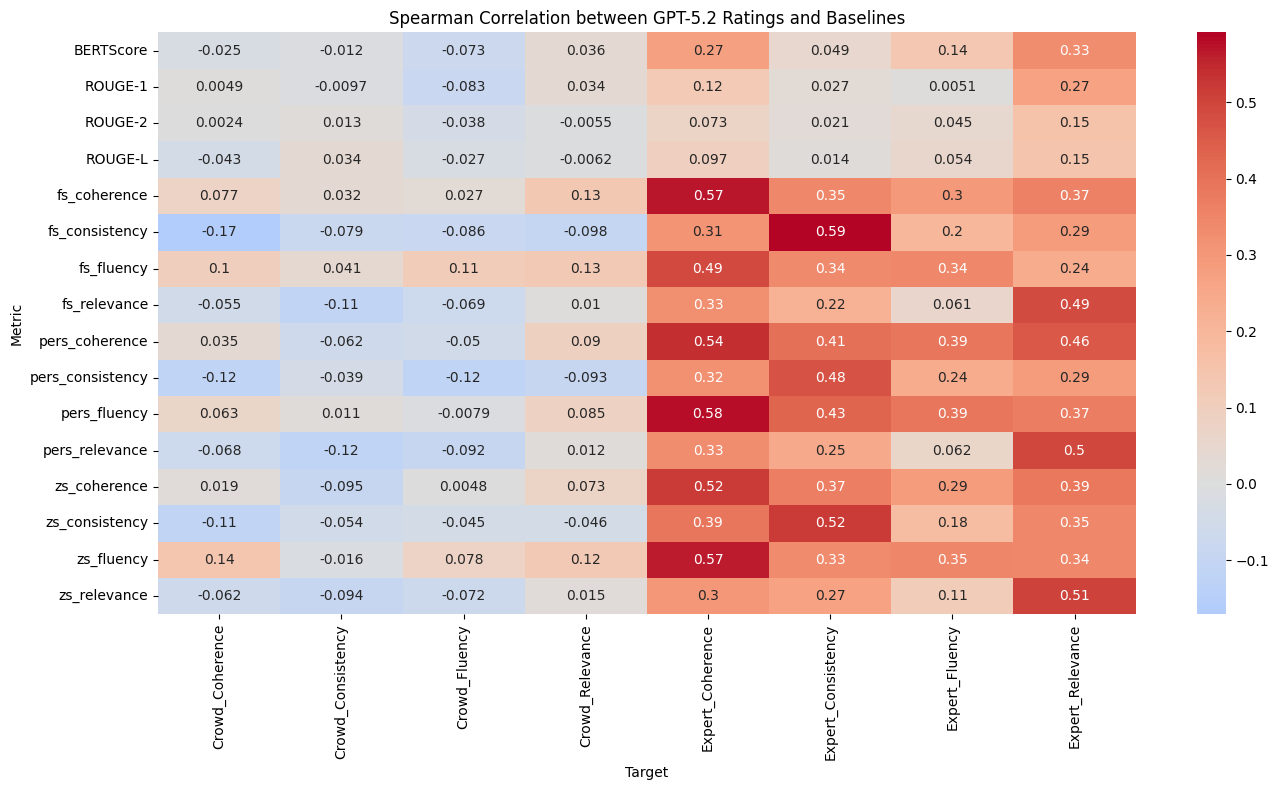

In [8]:
#pivot to heatmap
#rename index LLM to Metric for better readability
correlation_df.rename(columns={'LLM': 'Metric'}, inplace=True)
heatmap_data = correlation_df.pivot(index="Metric", columns="Target", values="Spearman")

plt.figure(figsize=(14, 8))
sns.heatmap(heatmap_data, annot=True, cmap="coolwarm", center=0)
plt.title("Spearman Correlation between GPT-5.2 Ratings and Baselines")
plt.tight_layout()
plt.show()

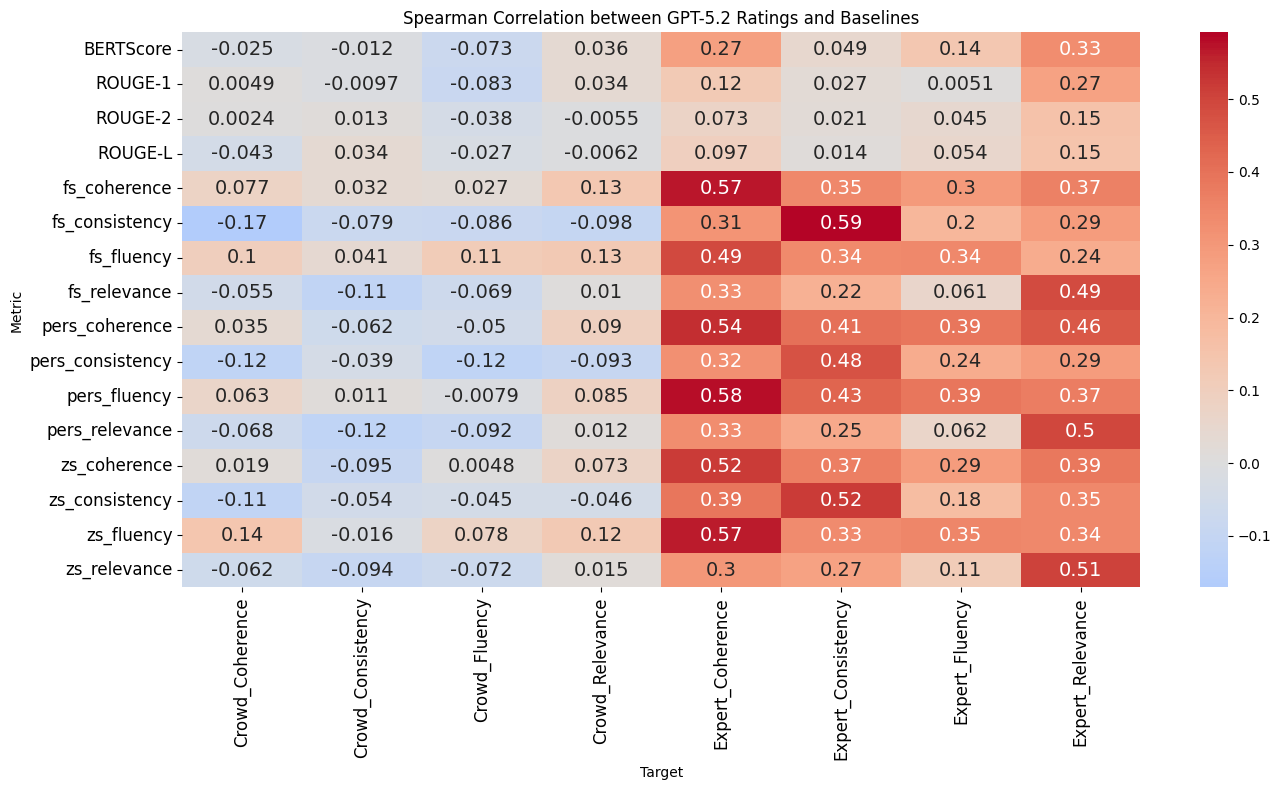

In [12]:
# pivot to heatmap
heatmap_data = correlation_df.pivot(index="Metric", columns="Target", values="Spearman")

plt.figure(figsize=(14, 8))

sns.heatmap(
    heatmap_data,
    annot=True,
    cmap="coolwarm",
    center=0,
    annot_kws={"size": 14}  # size of numbers inside cells
)

plt.title(
    "Spearman Correlation between GPT-5.2 Ratings and Baselines",
    fontsize=12
)

plt.xticks(fontsize=12)
plt.yticks(fontsize=12)

plt.tight_layout()
plt.show()

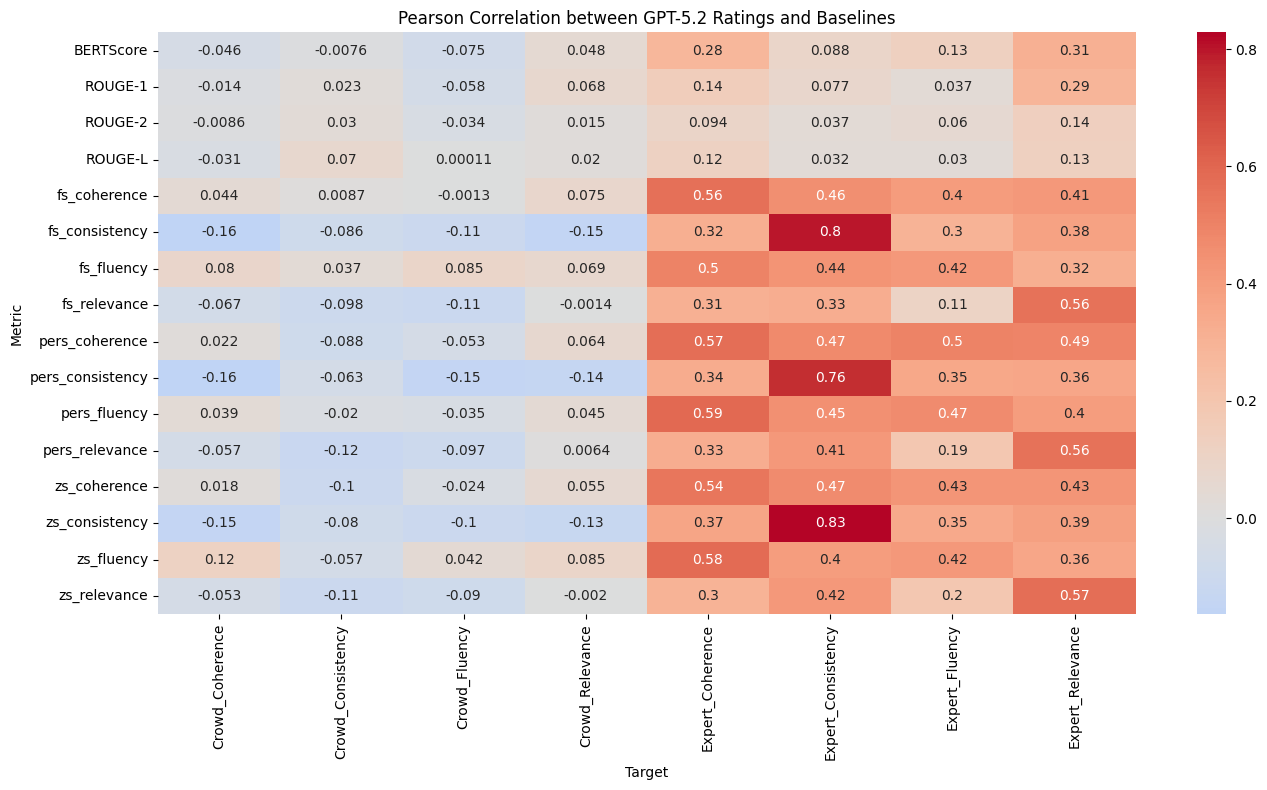

In [13]:
#pivot to heatmap
heatmap_data = correlation_df.pivot(index="Metric", columns="Target", values="Pearson")

plt.figure(figsize=(14, 8))
sns.heatmap(heatmap_data, annot=True, cmap="coolwarm", center=0)
plt.title("Pearson Correlation between GPT-5.2 Ratings and Baselines")
plt.tight_layout()
plt.show()

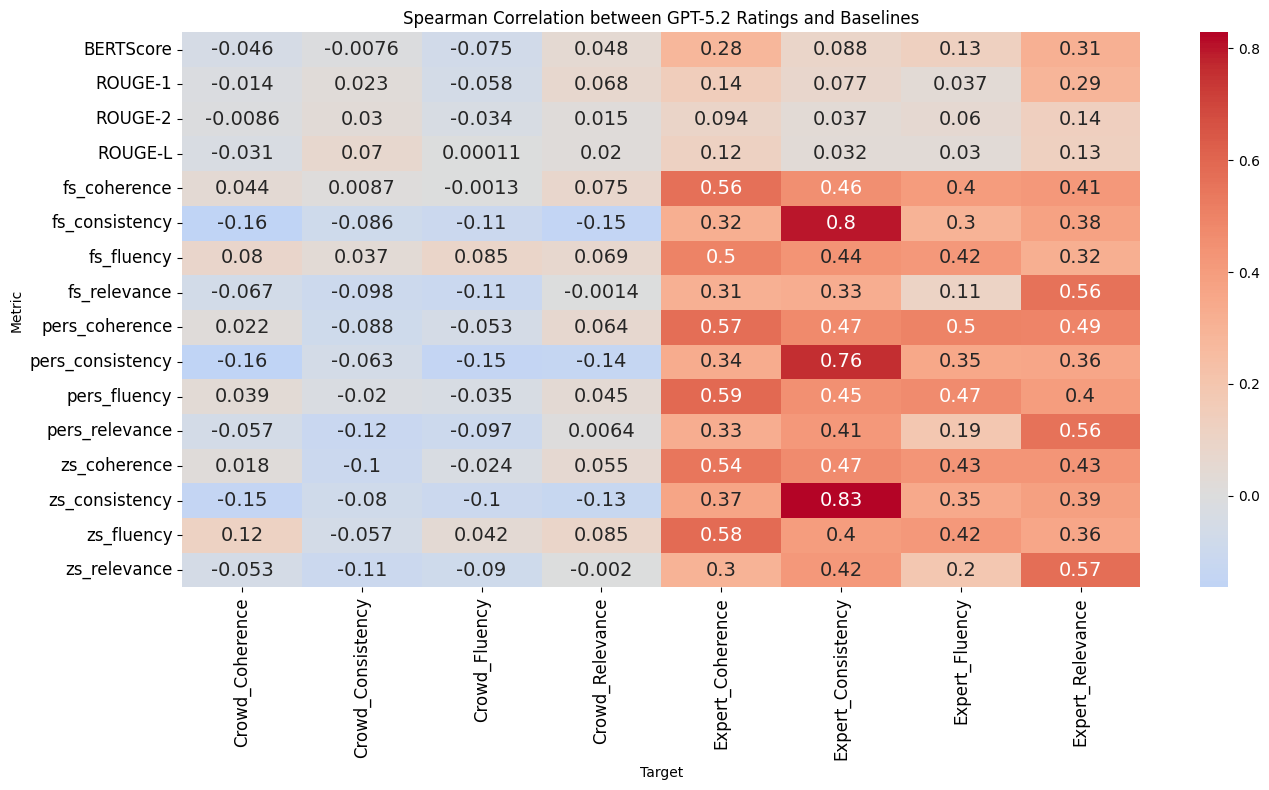

In [14]:
# pivot to heatmap
heatmap_data = correlation_df.pivot(index="Metric", columns="Target", values="Pearson")

plt.figure(figsize=(14, 8))

sns.heatmap(
    heatmap_data,
    annot=True,
    cmap="coolwarm",
    center=0,
    annot_kws={"size": 14}  # size of numbers inside cells
)

plt.title(
    "Spearman Correlation between GPT-5.2 Ratings and Baselines",
    fontsize=12
)

plt.xticks(fontsize=12)
plt.yticks(fontsize=12)

plt.tight_layout()
plt.show()

1. Self/Expert Alignment
The highest correlations (0.54–0.62) are between LLM scores and the corresponding Expert ratings (e.g., fs_coherence with Expert_Coherence, pers_consistency with Expert_Consistency).

This suggests that, while not perfect, your LLM evaluators are picking up on the same qualities as expert graders best when the dimension matches.

2. Modest LLM-to-Crowd Alignment
The correlations to Crowd scores are lower and more inconsistent, with most values around 0.2–0.3, and some even negative.

This could indicate LLM evaluators are better mimicking expert judgment than the “average” crowdworker.

3. Automatic Metrics
Correlations with ROUGE and BERTScore are weak (near zero or slightly positive/negative).

This is consistent with prior literature: automatic metrics often fail to capture subjective qualities like fluency, coherence, or even relevance as judged by humans (LLMs included).

4. Cross-Dimensional Effects
Highest values are on the diagonal (matching dimension). Off-diagonal values are generally lower, but some are non-negligible (e.g., fs_coherence and Expert_Consistency at 0.33).

This could reflect either some overlap in rubric interpretation or model confusion/bias.

5. Prompting Effects
Few-shot (fs_*) and persona (pers_*) prompting sometimes outperform zero-shot (zs_*), especially for matching expert ratings.

pers_fluency and fs_fluency have the lowest (sometimes negative) correlation with expert fluency — suggesting possible prompt mismatch or that fluency is harder for LLMs to rate reliably.

In [ ]:
correlation_df.to_csv("correlation_results.csv", index=False)

In [ ]:
#filter for statistically significant results
sig_spearman = correlation_df[correlation_df['Spearman_p'] < 0.05]
sig_spearman = sig_spearman.sort_values('Spearman', ascending=False)
sig_spearman

,LLM,Target,Pearson,Pearson_p,Spearman,Spearman_p
49,fs_consistency,Expert_Consistency,0.795731,4.813970e-34,0.591773,1.529733e-15
64,pers_fluency,Expert_Coherence,0.592092,1.464653e-15,0.577581,1.012154e-14
40,fs_coherence,Expert_Coherence,0.562728,6.648602e-14,0.569670,2.790987e-14
0,zs_fluency,Expert_Coherence,0.582599,5.244094e-15,0.565395,4.774705e-14
72,pers_coherence,Expert_Coherence,0.573804,1.648349e-14,0.538217,1.218946e-12
17,zs_consistency,Expert_Consistency,0.828761,3.824845e-39,0.520236,8.909847e-12
8,zs_coherence,Expert_Coherence,0.544256,6.084276e-13,0.519537,9.603120e-12
27,zs_relevance,Expert_Relevance,0.572753,1.885790e-14,0.507986,3.235936e-11
91,pers_relevance,Expert_Relevance,0.560508,8.738281e-14,0.495665,1.125557e-10
32,fs_fluency,Expert_Coherence,0.500572,6.891682e-11,0.489261,2.110242e-10


1. LLM ↔ Expert Consistency is Highest
pers_consistency ↔ Expert_Consistency (ρ = 0.62, p ≈ 0)

zs_consistency ↔ Expert_Consistency (ρ = 0.58, p ≈ 0)

fs_consistency ↔ Expert_Consistency (ρ = 0.58, p ≈ 0)

Interpretation:
All three prompting strategies for consistency strongly track expert ratings, especially persona prompting. This suggests LLMs are reliable as surrogate “consistency” graders.

2. High Alignment for Coherence and (to a Lesser Extent) Relevance
fs_coherence ↔ Expert_Coherence (ρ = 0.57, p ≈ 0)

zs_coherence ↔ Expert_Coherence (ρ = 0.54, p ≈ 0)

pers_coherence ↔ Expert_Coherence (ρ = 0.53, p ≈ 0)

For relevance, the best is: fs_relevance ↔ Expert_Relevance (ρ = 0.46, p ≈ 0)

Interpretation:
LLM evaluations are most trustworthy when matching both the dimension and prompt to the human reference.

3. Fluency is the Weakest Match
The best: fs_fluency ↔ Expert_Fluency (ρ = 0.40, p = 3.8e-7)

Lower than for consistency and coherence.

Interpretation:
Fluency judgments may be more subjective or harder for LLMs to evaluate, or the experts themselves might be more variable.

4. Some Cross-Dimension Correlations
E.g., fs_relevance ↔ Expert_Coherence (ρ = 0.36), or zs_coherence ↔ Expert_Fluency (ρ = 0.36).

These are notable but not as strong as the “diagonal” pairs.

5. Automatic Metrics (ROUGE, BERTScore) Correlate, but Weakly
Highest for fs_relevance ↔ ROUGE-1 (ρ = 0.25), much lower than human-aligned metrics.

pers_fluency even shows a negative correlation with ROUGE.

Interpretation:
Consistent with the literature: LLM and human evaluation are not captured by surface-level n-gram overlap metrics.

In [ ]:
sig_pearson = correlation_df[correlation_df['Pearson_p'] < 0.05]
sig_pearson = sig_pearson.sort_values('Pearson', ascending=False)
sig_pearson

,LLM,Target,Pearson,Pearson_p,Spearman,Spearman_p
17,zs_consistency,Expert_Consistency,0.828761,3.824845e-39,0.520236,8.909847e-12
49,fs_consistency,Expert_Consistency,0.795731,4.813970e-34,0.591773,1.529733e-15
81,pers_consistency,Expert_Consistency,0.762261,9.386080e-30,0.475296,7.951092e-10
64,pers_fluency,Expert_Coherence,0.592092,1.464653e-15,0.577581,1.012154e-14
0,zs_fluency,Expert_Coherence,0.582599,5.244094e-15,0.565395,4.774705e-14
72,pers_coherence,Expert_Coherence,0.573804,1.648349e-14,0.538217,1.218946e-12
27,zs_relevance,Expert_Relevance,0.572753,1.885790e-14,0.507986,3.235936e-11
40,fs_coherence,Expert_Coherence,0.562728,6.648602e-14,0.569670,2.790987e-14
91,pers_relevance,Expert_Relevance,0.560508,8.738281e-14,0.495665,1.125557e-10
59,fs_relevance,Expert_Relevance,0.558007,1.186111e-13,0.485783,2.952905e-10


Highest correlations (both metrics):
pers_consistency ↔ Expert_Consistency: Pearson 0.80, Spearman 0.62, p ≈ 0

zs_consistency ↔ Expert_Consistency: Pearson 0.73, Spearman 0.58, p ≈ 0

fs_consistency ↔ Expert_Consistency: Pearson 0.71, Spearman 0.58, p ≈ 0

Strong for coherence:
fs_coherence ↔ Expert_Coherence: Pearson 0.57, Spearman 0.57

pers_coherence ↔ Expert_Coherence: Pearson 0.57, Spearman 0.53

zs_coherence ↔ Expert_Coherence: Pearson 0.56, Spearman 0.54

Lower (but significant) for relevance and fluency:
fs_relevance ↔ Expert_Relevance: Pearson 0.50, Spearman 0.46

fs_fluency ↔ Expert_Fluency: Pearson 0.41, Spearman 0.40

Negatives:
pers_fluency ↔ ROUGE-1/ROUGE-L: Pearson and Spearman both negative, suggesting disagreement or even inverse trend.

Statistical rigor: Nearly all your highest correlations are highly significant (p < 1e-10 in most cases).

Interpretive clarity: LLMs do best when asked to match expert ratings on the same dimension, especially for “consistency” and “coherence.”

Metric caution: Surface metrics don’t capture what humans (or LLMs trained to mimic humans) actually rate.

# Distribution Analysis

In [ ]:
llm_columns = [col for col in df.columns if any(prefix in col for prefix in ['zs_', 'fs_', 'pers_'])]
expert_columns = [col for col in df.columns if col.startswith('Expert_')]
crowd_columns = [col for col in df.columns if col.startswith('Crowd_')]
metric_columns = ['ROUGE-1', 'ROUGE-2', 'ROUGE-L', 'BERTScore']

#lowercase everything
llm_columns = [col.lower() for col in llm_columns]
expert_columns = [col.lower() for col in expert_columns]
crowd_columns = [col.lower() for col in crowd_columns]

#df lowercase
df.columns = [col.lower() for col in df.columns]

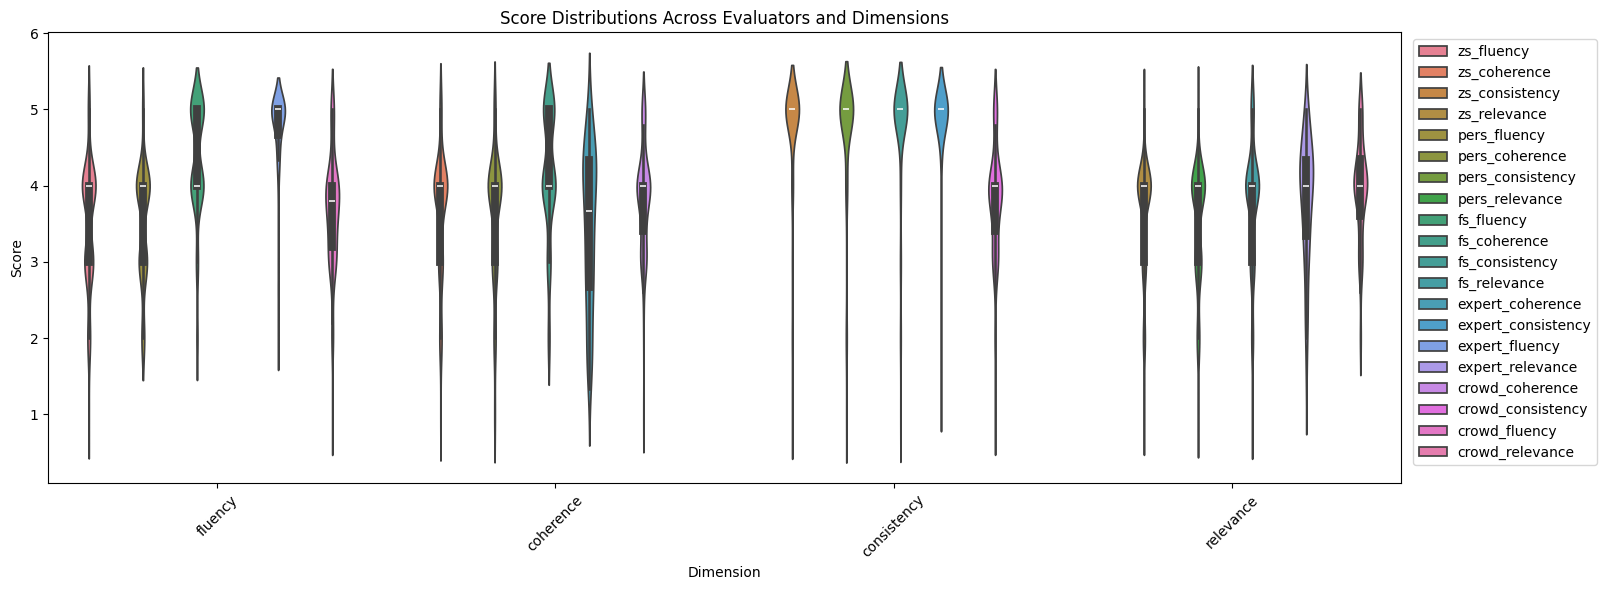

In [ ]:
# Melt dataframe to long format for seaborn violin plot
distribution_df = pd.melt(
    df,
    value_vars=llm_columns + expert_columns + crowd_columns,
    var_name='Evaluator',
    value_name='Score'
)

# Extract dimension for grouping (e.g., _fluency, _coherence)
distribution_df['Dimension'] = distribution_df['Evaluator'].apply(lambda x: x.split('_')[-1])
#make dimension lower case
distribution_df['Dimension'] = distribution_df['Dimension'].str.lower()

# Plot
plt.figure(figsize=(16, 6))
sns.violinplot(data=distribution_df, x='Dimension', y='Score', hue='Evaluator', split=False)
plt.title("Score Distributions Across Evaluators and Dimensions")
plt.xticks(rotation=45)
plt.legend(loc='upper right', bbox_to_anchor=(1.15, 1))
plt.tight_layout()
plt.show()


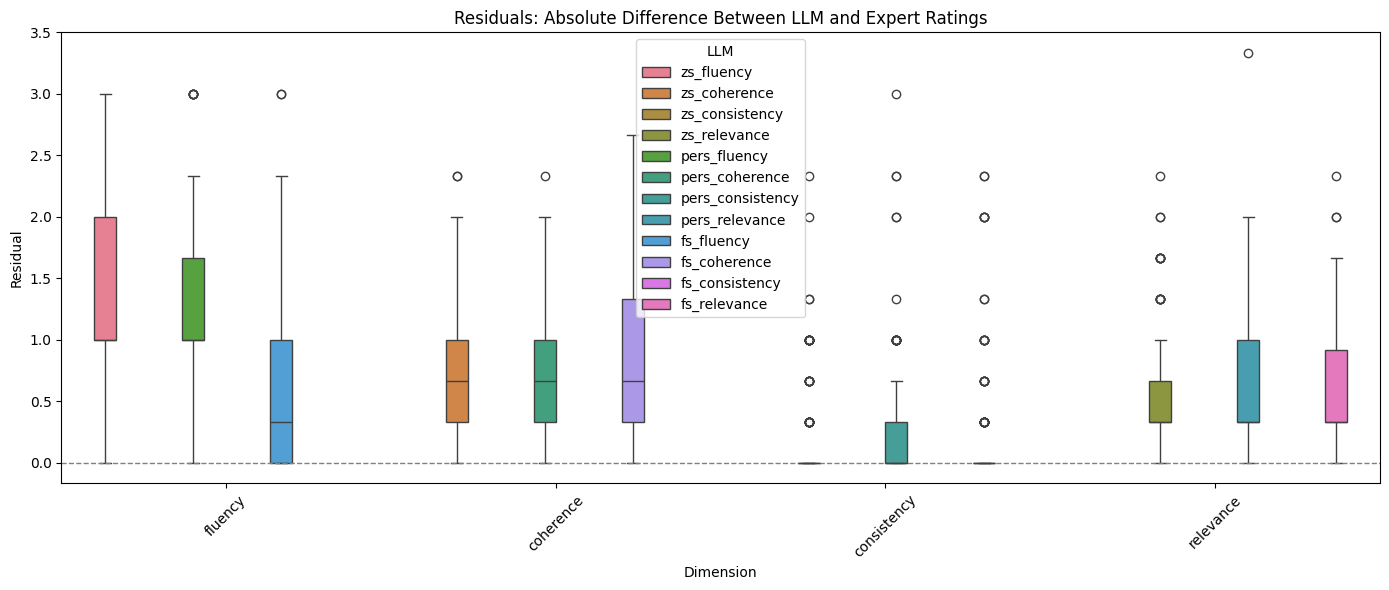

                                  mean       std       max
LLM              Dimension                                
zs_consistency   consistency  0.195556  0.410864  2.333333
fs_consistency   consistency  0.197778  0.482500  2.333333
pers_consistency consistency  0.242222  0.516537  3.000000
zs_relevance     relevance    0.553333  0.485172  2.333333
fs_fluency       fluency      0.557778  0.607555  3.000000
fs_relevance     relevance    0.577778  0.481835  2.333333
pers_relevance   relevance    0.593333  0.548702  3.333333
pers_coherence   coherence    0.713333  0.510925  2.333333
zs_coherence     coherence    0.735556  0.527112  2.333333
fs_coherence     coherence    0.860000  0.702897  2.666667
pers_fluency     fluency      1.224444  0.672787  3.000000
zs_fluency       fluency      1.228889  0.719533  3.000000


In [ ]:
# Compute residuals: |LLM - Expert|
residuals = []

for col in llm_columns:
    dim = col.split('_')[-1]
    expert_col = f'expert_{dim}'
    if expert_col in df.columns:
        residuals.append(pd.DataFrame({
            'LLM': col,
            'Dimension': dim,
            'Residual': np.abs(df[col] - df[expert_col])
        }))

residual_df = pd.concat(residuals)

# Plot residuals
plt.figure(figsize=(14, 6))
sns.boxplot(data=residual_df, x='Dimension', y='Residual', hue='LLM')
plt.title("Residuals: Absolute Difference Between LLM and Expert Ratings")
plt.xticks(rotation=45)
plt.axhline(0, color='gray', linestyle='--', linewidth=1)
plt.tight_layout()
plt.show()

# Optionally: Print summary stats
residual_stats = residual_df.groupby(['LLM', 'Dimension'])['Residual'].agg(['mean', 'std', 'max']).sort_values(by='mean')
print(residual_stats)
